# Regression Model Comparison

Compare Linear Regression, Random Forest Regressor, and XGBoost Regressor to predict asteroid diameter. The notebook uses only rows with an observed diameter from the original dataset (so imputed target values are never treated as measurements), samples at most 200,000 eligible records for practical runtime, and saves the best estimator with its preprocessing pipeline as a reusable model artifact. No new data CSV is created.

## 1. Import libraries and locate the original data

In [36]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Data" / "pha_dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "Data" / "pha_dataset.csv"
TARGET = "diameter"
MAX_ROWS = 200_000
MAX_TRAIN_ROWS = 50_000
RANDOM_STATE = 42
print("Input dataset:", DATA_PATH)

Input dataset: d:\Guvi\PDA\Data\pha_dataset.csv


## 2. Load rows with a measured regression target

The cleaned CSV may contain median-imputed `diameter` values. To avoid training against fabricated target values, this notebook reads the original CSV and drops rows where diameter was missing.

In [26]:
excluded_columns = {
    "id", "spkid", "full_name", "pdes", "name", "prefix", "orbit_id",
    "pha", "neo", "diameter_sigma",
}
data = pd.read_csv(
    DATA_PATH,
    low_memory=False,
    usecols=lambda column: column not in excluded_columns,
)
initial_rows = len(data)
data[TARGET] = pd.to_numeric(data[TARGET], errors="coerce")
data = data.dropna(subset=[TARGET]).copy()
data = data[data[TARGET] >= 0].copy()
print(f"Rows loaded: {initial_rows:,}")
print(f"Rows with valid observed diameter: {len(data):,}")
print(f"Rows excluded for missing/invalid diameter: {initial_rows - len(data):,}")
print(f"Diameter range: {data[TARGET].min():.3f} to {data[TARGET].max():.3f} km")
display(data.head())

Rows loaded: 958,524
Rows with valid observed diameter: 136,209
Rows excluded for missing/invalid diameter: 822,315
Diameter range: 0.003 to 939.400 km


,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,3.40,939.400,0.0900,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,4.20,545.000,0.1010,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,5.33,246.596,0.2140,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,3.00,525.400,0.4228,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,6.90,106.699,0.2740,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


## 3. Set up predictors and make a reproducible sample

Absolute magnitude (`H`) is included as the brightness feature, with albedo and orbital/physical measurements as additional predictors. IDs, names, target flags, and diameter uncertainty are excluded. If there are more than 200,000 observed targets, a reproducible random sample is used for faster training.

In [27]:
if len(data) > MAX_ROWS:
    data = data.sample(n=MAX_ROWS, random_state=RANDOM_STATE)
    print(f"Randomly sampled {MAX_ROWS:,} records for training and evaluation.")

X = data.drop(columns=[TARGET]).copy()
y = data[TARGET].astype(float).copy()
for column in X.select_dtypes(include=["object", "string"]).columns:
    X[column] = X[column].str.strip().replace("", pd.NA)

numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
unsupported_columns = [column for column in X.columns if column not in numeric_columns + categorical_columns]
if unsupported_columns:
    raise TypeError(f"Unsupported predictor types: {unsupported_columns}")
print(f"Predictors: {X.shape[1]} ({len(numeric_columns)} numeric, {len(categorical_columns)} categorical)")
print("Numeric predictors:", numeric_columns)
print("Categorical predictors:", categorical_columns)
display(y.describe().to_frame("diameter_km"))

Predictors: 34 (32 numeric, 2 categorical)
Numeric predictors: ['H', 'albedo', 'epoch', 'epoch_mjd', 'epoch_cal', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w', 'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per', 'rms']
Categorical predictors: ['equinox', 'class']


,diameter_km
count,136209.000000
mean,5.506429
std,9.425164
min,0.002500
25%,2.780000
50%,3.972000
75%,5.765000
max,939.400000


## 4. Split into training and test sets

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print(f"Training target median: {y_train.median():.3f} km")

Training rows: 108,967; test rows: 27,242
Training target median: 3.969 km


## 5. Impute, encode, and scale predictors

Preprocessing is fitted on training rows only. The target is modeled as `log1p(diameter)` because diameter values are strongly right-skewed; predictions are converted back to kilometers for evaluation.

In [29]:
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(with_mean=False),
)
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=True),
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
y_train_log = np.log1p(y_train)
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (108967, 44)
Processed test shape: (27242, 44)


## 6. Define the three regression models

In [30]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        max_samples=0.8,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "XGBoost Regressor": XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        eval_metric="rmse",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}
print("Models:", list(models))

Models: ['Linear Regression', 'Random Forest Regressor', 'XGBoost Regressor']


## 7. Train and evaluate models

To keep training practical, all three models use the same reproducible training subset of at most 50,000 rows. Evaluation still uses the full held-out test split. Metrics are calculated on the original diameter scale in kilometers. Lower MAE/RMSE is better; higher R-squared is better. RMSLE summarizes relative error and is defined here because all target diameters are non-negative.

In [31]:
predictions = {}
results = []
if len(y_train) > MAX_TRAIN_ROWS:
    fit_indices = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(y_train), size=MAX_TRAIN_ROWS, replace=False))
else:
    fit_indices = np.arange(len(y_train))
X_fit = X_train_processed[fit_indices]
y_fit = y_train_log.iloc[fit_indices]
print(f"Training each model on {len(fit_indices):,} rows; evaluating on {len(y_test):,} test rows.")

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_fit, y_fit)
    y_pred = np.expm1(model.predict(X_test_processed))
    y_pred = np.clip(y_pred, a_min=0, a_max=None)
    predictions[model_name] = y_pred
    results.append({
        "model": model_name,
        "MAE_km": mean_absolute_error(y_test, y_pred),
        "RMSE_km": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
        "RMSLE": np.sqrt(mean_squared_log_error(y_test, y_pred)),
    })
    print(f"{model_name} complete.")

results_df = pd.DataFrame(results).set_index("model").sort_values("RMSE_km")
display(results_df.style.format("{:.4f}"))

Training each model on 50,000 rows; evaluating on 27,242 test rows.
Training Linear Regression...
Linear Regression complete.
Training Random Forest Regressor...
Random Forest Regressor complete.
Training XGBoost Regressor...
XGBoost Regressor complete.


,MAE_km,RMSE_km,R2,RMSLE
model,,,,
XGBoost Regressor,0.4477,3.7394,0.8614,0.0852
Random Forest Regressor,0.4398,4.0193,0.8399,0.0854
Linear Regression,0.8456,5.2438,0.7274,0.1420


## 8. Compare predictions visually

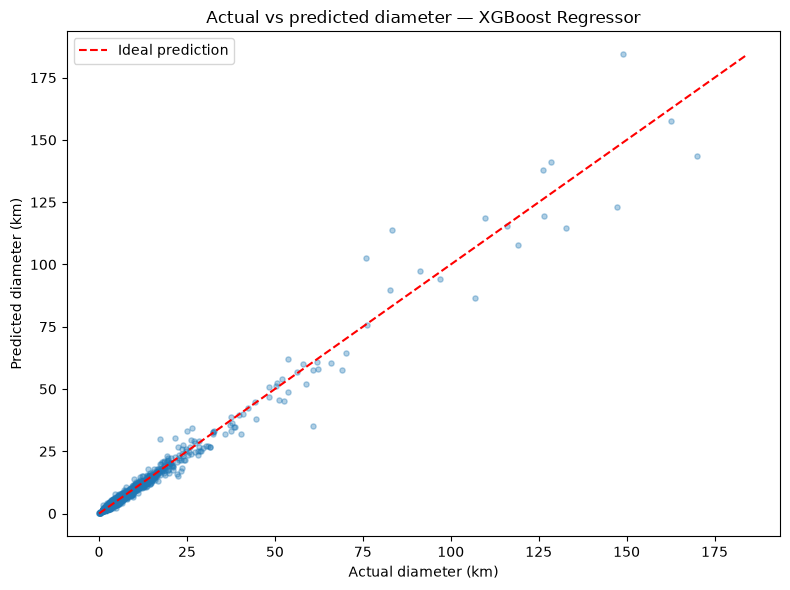

In [32]:
best_model_name = results_df["RMSE_km"].idxmin()
best_predictions = predictions[best_model_name]
plot_size = min(5_000, len(y_test))
plot_indices = np.random.default_rng(RANDOM_STATE).choice(len(y_test), size=plot_size, replace=False)

plt.figure(figsize=(8, 6))
plt.scatter(y_test.iloc[plot_indices], best_predictions[plot_indices], alpha=0.35, s=14)
max_value = max(float(y_test.iloc[plot_indices].max()), float(best_predictions[plot_indices].max()))
plt.plot([0, max_value], [0, max_value], color="red", linestyle="--", label="Ideal prediction")
plt.xlabel("Actual diameter (km)")
plt.ylabel("Predicted diameter (km)")
plt.title(f"Actual vs predicted diameter — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Best model summary

In [35]:
print(f"Best model by test RMSE: {best_model_name}")
display(results_df.loc[[best_model_name]].style.format("{:.4f}"))
print("All trained estimators remain available in the `models` dictionary.")

MODEL_PATH = PROJECT_ROOT / "Models" / "asteroid_diameter_regressor.pkl"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model_artifact = {
    "model": models[best_model_name],
    "preprocessor": preprocessor,
    "feature_columns": feature_columns if "feature_columns" in globals() else X.columns.tolist(),
    "target_column": TARGET,
    "target_transform": "log1p",
    "prediction_inverse_transform": "expm1, clipped at zero",
    "target_units": "km",
    "model_name": best_model_name,
}
with MODEL_PATH.open("wb") as model_file:
    pickle.dump(model_artifact, model_file, protocol=pickle.HIGHEST_PROTOCOL)

# Verify the saved model/preprocessor reproduces the selected model's test predictions.
with MODEL_PATH.open("rb") as model_file:
    loaded_artifact = pickle.load(model_file)
loaded_predictions = np.expm1(
    loaded_artifact["model"].predict(loaded_artifact["preprocessor"].transform(X_test))
)
loaded_predictions = np.clip(loaded_predictions, a_min=0, a_max=None)
np.testing.assert_allclose(loaded_predictions, predictions[best_model_name], rtol=1e-6, atol=1e-8)
print(f"Saved and verified regression model: {MODEL_PATH}")
print("No new data CSV was created.")

Best model by test RMSE: XGBoost Regressor


,MAE_km,RMSE_km,R2,RMSLE
model,,,,
XGBoost Regressor,0.4477,3.7394,0.8614,0.0852


All trained estimators remain available in the `models` dictionary.
Saved and verified regression model: d:\Guvi\PDA\Models\asteroid_diameter_regressor.pkl
No new data CSV was created.


## 10. Explain the selected regressor with SHAP

TreeSHAP explains the saved best-performing XGBoost regressor on a reproducible sample of measured-diameter records. Tree-path-dependent explanations use the model's training-path statistics. Since the model was trained on `log1p(diameter)`, SHAP values and the individual waterfall plot are in log1p-diameter units. SHAP ranks `H` and `albedo` as the strongest predictors, followed by orbital/uncertainty variables including `a`, `n`, and `sigma_n`. Step 5's PHA-classification selector has some overlap (`class`, `a`, `n`, `rms`, `q`, and other orbital/uncertainty features), but not the top diameter predictors `H` and `albedo`; this is only partial alignment because the target differs.

Explained model: XGBoost Regressor; SHAP output: log1p(diameter in km)
Waterfall row: predicted=3.0436 km; measured=2.5090 km
Measured-diameter rows explained: 300; transformed predictors: 44


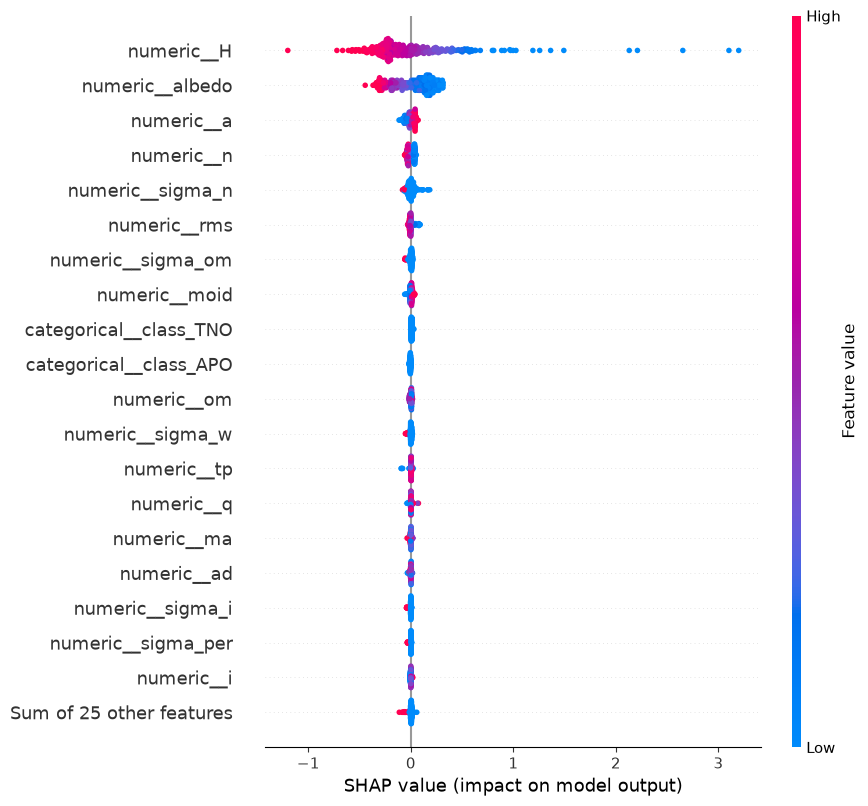

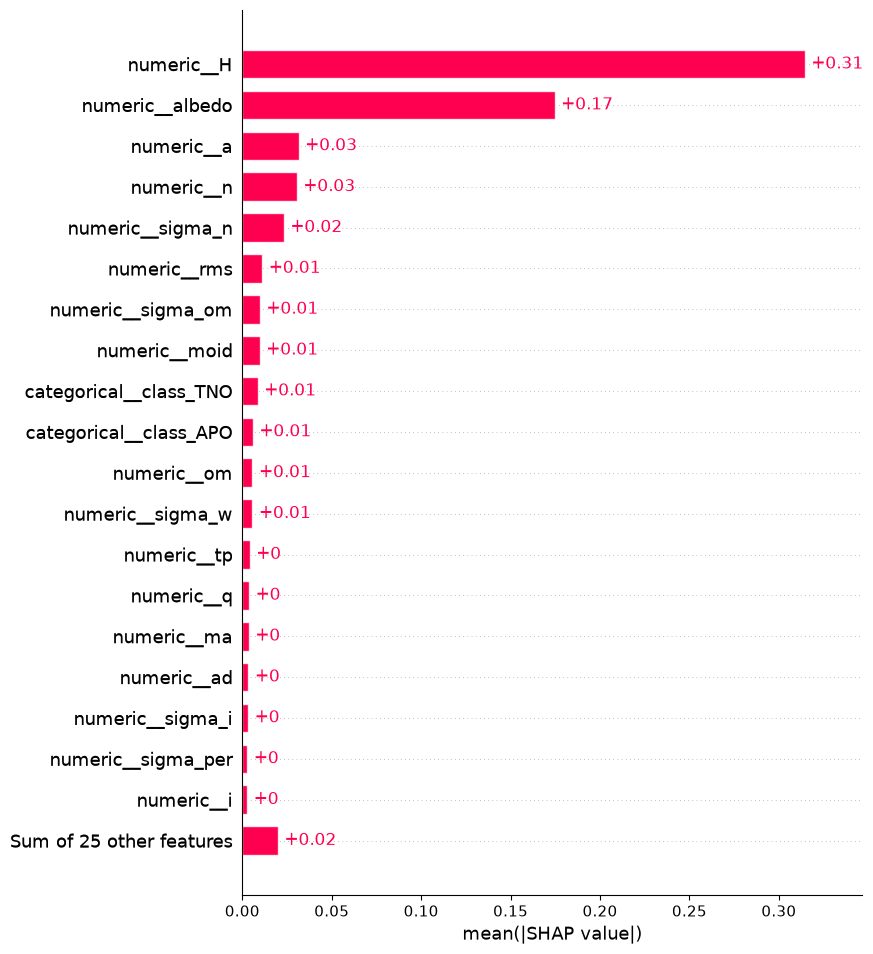

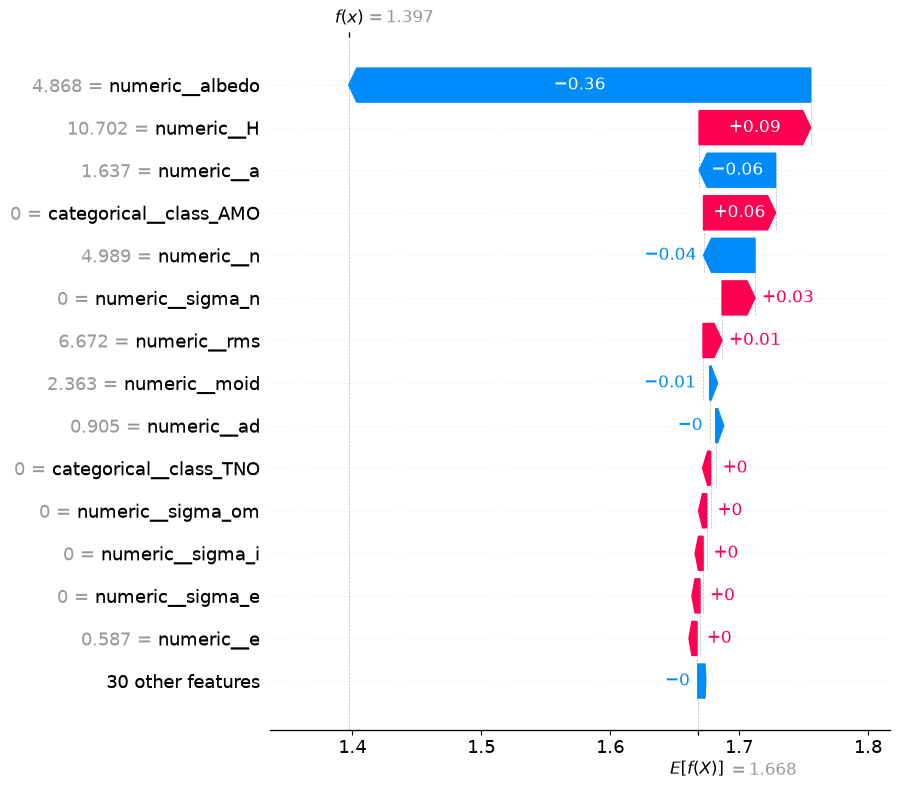

,mean_abs_shap (grouped by source predictor)
source_feature,
H,0.314435
albedo,0.174579
a,0.031410
n,0.030384
sigma_n,0.023149
class,0.017767
rms,0.011102
sigma_om,0.009741
moid,0.009659


Step 5 top-20 features: ['q', 'class_MBA', 'class_APO', 'e', 'n', 'per', 'per_y', 'ad', 'a', 'rms', 'sigma_per', 'sigma_ad', 'sigma_tp', 'sigma_a', 'sigma_i', 'sigma_e', 'sigma_q', 'i', 'sigma_n', 'om']
Shared source features in both top-20 lists: ['q', 'class', 'n', 'ad', 'a', 'rms', 'sigma_per', 'sigma_a', 'sigma_i', 'i', 'sigma_n', 'om']
Step 5 selected features for PHA classification, not diameter prediction; shared rankings are indicative only.


In [41]:
import shap
from scipy import sparse

with (PROJECT_ROOT / "Models" / "asteroid_diameter_regressor.pkl").open("rb") as model_file:
    shap_artifact = pickle.load(model_file)
shap_target = shap_artifact["target_column"]
shap_columns = shap_artifact["feature_columns"]
shap_data = pd.read_csv(DATA_PATH, usecols=list(dict.fromkeys(shap_columns + [shap_target])))
shap_data = shap_data.dropna(subset=[shap_target])
shap_data = shap_data.sample(n=min(1_200, len(shap_data)), random_state=RANDOM_STATE).reset_index(drop=True)
shap_raw = shap_data[shap_columns]
shap_matrix = shap_artifact["preprocessor"].transform(shap_raw)
if sparse.issparse(shap_matrix):
    shap_matrix = shap_matrix.toarray()
shap_feature_names = shap_artifact["preprocessor"].get_feature_names_out().tolist()
explanation_size = min(300, len(shap_matrix))
shap_explain_data = shap_matrix[:explanation_size]

shap_explainer = shap.TreeExplainer(
    shap_artifact["model"],
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)
shap_raw_values = shap_explainer.shap_values(shap_explain_data, check_additivity=False)
if isinstance(shap_raw_values, list):
    shap_values_array = np.asarray(shap_raw_values[0])
else:
    shap_values_array = np.asarray(shap_raw_values)
    if shap_values_array.ndim == 3:
        shap_values_array = shap_values_array[:, :, 0]
shap_base = float(np.asarray(shap_explainer.expected_value).reshape(-1)[0])
shap_explanation = shap.Explanation(
    values=shap_values_array,
    base_values=np.full(len(shap_explain_data), shap_base),
    data=shap_explain_data,
    feature_names=shap_feature_names,
)

shap_model_log_prediction = shap_artifact["model"].predict(shap_explain_data[:1])[0]
shap_predicted_diameter_km = max(0.0, np.expm1(shap_model_log_prediction))
shap_actual_diameter_km = shap_data.iloc[0][shap_target]
print(f"Explained model: {shap_artifact['model_name']}; SHAP output: log1p(diameter in km)")
print(f"Waterfall row: predicted={shap_predicted_diameter_km:.4f} km; measured={shap_actual_diameter_km:.4f} km")
print(f"Measured-diameter rows explained: {len(shap_explain_data):,}; transformed predictors: {len(shap_feature_names)}")
shap.plots.beeswarm(shap_explanation, max_display=20)
shap.plots.bar(shap_explanation, max_display=20)
shap.plots.waterfall(shap_explanation[0], max_display=15)

def original_predictor(encoded_name):
    unprefixed = encoded_name.split("__", 1)[-1]
    for source_name in sorted(shap_columns, key=len, reverse=True):
        if unprefixed == source_name or unprefixed.startswith(source_name + "_"):
            return source_name
    return unprefixed

shap_encoded_importance = pd.DataFrame({
    "encoded_feature": shap_feature_names,
    "mean_abs_shap": np.abs(shap_values_array).mean(axis=0),
})
shap_encoded_importance["source_feature"] = shap_encoded_importance["encoded_feature"].map(original_predictor)
shap_source_importance = (
    shap_encoded_importance.groupby("source_feature")["mean_abs_shap"]
    .sum()
    .sort_values(ascending=False)
)
display(shap_source_importance.head(20).rename("mean_abs_shap (grouped by source predictor)").to_frame())

step5_importance_path = PROJECT_ROOT / "Data" / "pha_feature_importance.csv"
step5_importance = pd.read_csv(step5_importance_path)
step5_top_features = step5_importance["feature"].head(20).tolist()
shap_top_features = shap_source_importance.head(20).index.tolist()
step5_source_features = [original_predictor(name) for name in step5_top_features]
print("Step 5 top-20 features:", step5_top_features)
shared_source_features = list(dict.fromkeys(name for name in step5_source_features if name in shap_top_features))
print("Shared source features in both top-20 lists:", shared_source_features)
print("Step 5 selected features for PHA classification, not diameter prediction; shared rankings are indicative only.")